# GP Derivatives — The Gradient Posterior

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/gp_derivatives.ipynb)

A fitted GP emulator gives more than predictions: the gradient of a GP is itself a GP, so the posterior over $\nabla f(x_*)$ is Gaussian and exact. Its mean is the sensitivity map of Johnson et al. (2020); its covariance puts error bars on that map. This notebook uses `ConditionedGP.predict_gradient`, `predict_var_gradient` and `predict_mean_hessian`.

**What you'll learn:**

1. The gradient posterior and how it reuses the cached training solve.
2. A 1-D posterior slope with a $\pm 2\sigma$ band, against the slope of the truth.
3. A 2-D sensitivity map $\lVert \mathbb{E}\nabla f \rVert$ with its marginal uncertainty, and the $\nabla \sigma^2$ acquisition arrows.

## Background

### The gradient posterior

Take $f \sim \mathcal{GP}(m, k)$, observations $y = f(X) + \varepsilon$, $\varepsilon \sim \mathcal{N}(0, \sigma^2 I)$, and write $\hat K = K(X, X) + (\text{jitter} + \sigma^2) I$ and $\alpha = \hat K^{-1}(y - m(X))$ (the solve `GPPrior.condition` caches). Differentiation is linear, so $(\nabla f(x_*), y)$ is jointly Gaussian with cross-covariance $G(x_*) = \partial_1 K(x_*, X) \in \mathbb{R}^{D \times N}$, $G_{dn} = \partial k(x_*, x_n) / \partial x_{*,d}$ (Solak et al. 2003; Rasmussen & Williams 2006, §9.4). Conditioning gives

$$\mathbb{E}[\nabla f(x_*) \mid y] = \nabla m(x_*) + G(x_*)\,\alpha, \qquad \operatorname{Cov}[\nabla f(x_*) \mid y] = \nabla_x \nabla_{x'}^\top k(x_*, x_*) - G(x_*)\,\hat K^{-1} G(x_*)^\top .$$

The mean equals $\nabla_{x_*} \mu_*(x_*)$, the derivative of the predictive mean that Johnson et al. (2020, §3) use for sensitivity analysis. With the cached Cholesky factor $\hat K = L L^\top$ the downdate is $V^\top V$ with $V = L^{-1} G^\top$: triangular solves only, no new factorisation.

### The gradient of the predictive variance

From $\sigma^2_*(x) = k(x, x) - k(x, X)\,\hat K^{-1} k(X, x)$,

$$\nabla_x \sigma^2_*(x) = \big[\partial_1 k + \partial_2 k\big](x, x) - 2\,G(x)\,\hat K^{-1} k(X, x),$$

whose first term vanishes for a stationary kernel. Ascending it moves a candidate towards where the model is least certain (uncertainty sampling).

### Pseudocode (what `predict_gradient` does)

```text
k    = freeze(kernel)                          # one hyperparameter draw per call
G    = [Derivative(k, dx=d)(X*, X) for d]      # (D*M, N), rows (d m)
mean = rearrange(G @ alpha, "(d m) -> m d") + grad m(X*)
V    = L^-1 G^T                                # cached factor; else K^-1 G^T via the solver
cov  = H(X*) - V^T V                           # per-point (M, D, D) blocks by default
```

**References.** Johnson, Laparra, Pérez-Suay, Mahecha & Camps-Valls (2020), *Kernel methods and their derivatives: Concept and perspectives for the earth system sciences*, PLOS ONE 15(10): e0235885, [doi:10.1371/journal.pone.0235885](https://doi.org/10.1371/journal.pone.0235885). Solak, Murray-Smith, Leithead, Leith & Rasmussen (2003), *Derivative observations in Gaussian process models of dynamic systems*, NeurIPS 15. Rasmussen & Williams (2006), *Gaussian Processes for Machine Learning*, §9.4.

## Setup

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import importlib.util

import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import pyrox_gp as px


jax.config.update("jax_enable_x64", True)

try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p jax,equinox,numpyro,gaussx,kernellib,pyrox,matplotlib",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.6.5
kernellib : 0.0.17
pyrox     : 0.1.1
matplotlib: 3.10.9

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1-D: the posterior slope

Fit an RBF GP to noisy draws of $f(x) = \sin(3x) + 0.3x^2$, then ask for the gradient posterior on a grid. `cov="marginal"` (the default) returns one $D \times D$ block per point, here $1 \times 1$.

In [3]:
def f_true(x):
    return jnp.sin(3.0 * x) + 0.3 * x**2


noise_std = 0.1
X = jnp.sort(jr.uniform(jr.key(0), (25, 1), minval=-2.0, maxval=2.0), axis=0)
y = f_true(X[:, 0]) + noise_std * jr.normal(jr.key(1), (25,))
cond = px.GPPrior(px.RBF(init_lengthscale=0.5), X, jitter=1e-8).condition(
    y, jnp.array(noise_std**2)
)

X_grid = jnp.linspace(-2.5, 2.5, 300)[:, None]
post = cond.predict_gradient(X_grid)
slope, slope_std = post.mean[:, 0], jnp.sqrt(post.cov[:, 0, 0])
print("mean", post.mean.shape, "cov", post.cov.shape)

# Finite-difference slope of the truth, for reference.
h = 1e-4
fd_slope = (f_true(X_grid[:, 0] + h) - f_true(X_grid[:, 0] - h)) / (2 * h)

mean (300, 1) cov (300, 1, 1)


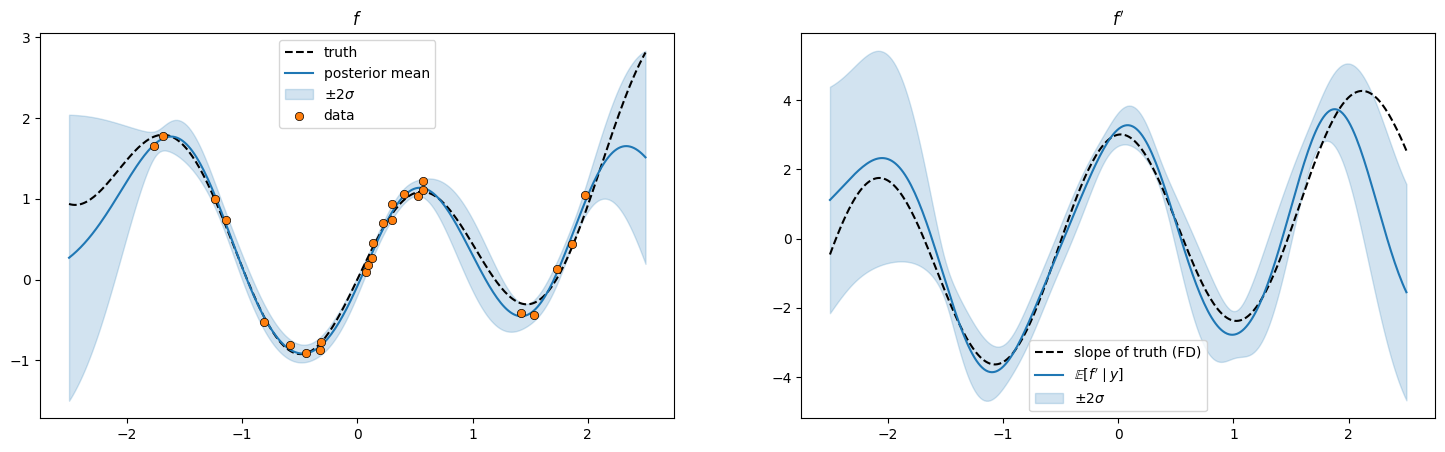

In [4]:
mu, var = cond.predict(X_grid)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
ax = axes[0]
ax.plot(X_grid[:, 0], f_true(X_grid[:, 0]), "k--", label="truth")
ax.plot(X_grid[:, 0], mu, color="C0", label="posterior mean")
ax.fill_between(
    X_grid[:, 0],
    mu - 2 * jnp.sqrt(var),
    mu + 2 * jnp.sqrt(var),
    color="C0",
    alpha=0.2,
    label=r"$\pm 2\sigma$",
)
ax.scatter(X[:, 0], y, c="C1", edgecolors="k", linewidths=0.5, zorder=5, label="data")
ax.set_title("$f$")
ax.legend()
ax = axes[1]
ax.plot(X_grid[:, 0], fd_slope, "k--", label="slope of truth (FD)")
ax.plot(X_grid[:, 0], slope, color="C0", label=r"$\mathbb{E}[f' \mid y]$")
ax.fill_between(
    X_grid[:, 0],
    slope - 2 * slope_std,
    slope + 2 * slope_std,
    color="C0",
    alpha=0.2,
    label=r"$\pm 2\sigma$",
)
ax.set_title("$f'$")
ax.legend()
plt.show()

The band widens outside the data, where the slope is unconstrained, and tightens between the points. Within the data the true slope stays inside the $\pm 2\sigma$ band.

## 2-D: a sensitivity map with uncertainty

On a 2-D input the gradient mean is a vector field; its norm $\lVert \mathbb{E}\nabla f \rVert$ is the sensitivity map, and the trace of the marginal covariance gives a scalar uncertainty for it. The input $x_2$ matters only through a weak trend, so the map should be dominated by $x_1$.

In [5]:
def g_true(Z):
    return jnp.sin(2.5 * Z[:, 0]) + 0.2 * Z[:, 1]


X2 = jr.uniform(jr.key(2), (60, 2), minval=-1.5, maxval=1.5)
y2 = g_true(X2) + 0.05 * jr.normal(jr.key(3), (60,))
cond2 = px.GPPrior(
    px.RBF(init_lengthscale=jnp.array([0.6, 1.5])), X2, jitter=1e-8
).condition(y2, jnp.array(0.05**2))

n = 40
g1, g2 = jnp.meshgrid(jnp.linspace(-2.0, 2.0, n), jnp.linspace(-2.0, 2.0, n))
Z = jnp.stack([g1.ravel(), g2.ravel()], axis=-1)
post2 = cond2.predict_gradient(Z)
sensitivity = jnp.sqrt(jnp.sum(post2.mean**2, axis=-1)).reshape(n, n)
grad_std = jnp.sqrt(jnp.trace(post2.cov, axis1=-2, axis2=-1)).reshape(n, n)

# Coarser grid for the arrows: E[grad f] and grad sigma^2.
m = 12
q1, q2 = jnp.meshgrid(jnp.linspace(-2.0, 2.0, m), jnp.linspace(-2.0, 2.0, m))
Q = jnp.stack([q1.ravel(), q2.ravel()], axis=-1)
grad_mean = cond2.predict_gradient(Q, cov="none").mean
grad_var = cond2.predict_var_gradient(Q)

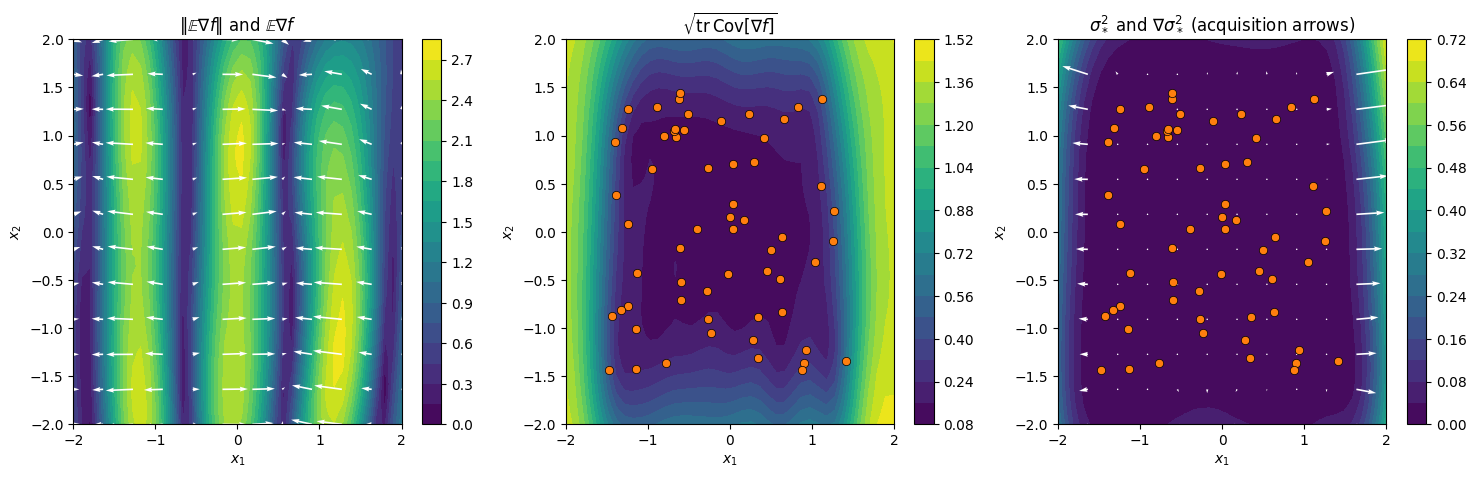

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
im = axes[0].contourf(g1, g2, sensitivity, levels=20)
axes[0].quiver(Q[:, 0], Q[:, 1], grad_mean[:, 0], grad_mean[:, 1], color="w")
axes[0].set_title(r"$\|\mathbb{E}\nabla f\|$ and $\mathbb{E}\nabla f$")
fig.colorbar(im, ax=axes[0])
im = axes[1].contourf(g1, g2, grad_std, levels=20)
axes[1].scatter(X2[:, 0], X2[:, 1], c="C1", edgecolors="k", linewidths=0.5, zorder=5)
axes[1].set_title(r"$\sqrt{\mathrm{tr}\,\mathrm{Cov}[\nabla f]}$")
fig.colorbar(im, ax=axes[1])
mu2, var2 = cond2.predict(Z)
im = axes[2].contourf(g1, g2, var2.reshape(n, n), levels=20)
axes[2].quiver(Q[:, 0], Q[:, 1], grad_var[:, 0], grad_var[:, 1], color="w")
axes[2].scatter(X2[:, 0], X2[:, 1], c="C1", edgecolors="k", linewidths=0.5, zorder=5)
axes[2].set_title(r"$\sigma^2_*$ and $\nabla\sigma^2_*$ (acquisition arrows)")
fig.colorbar(im, ax=axes[2])
for ax in axes:
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.show()

The sensitivity map follows $|2.5\cos(2.5 x_1)|$ inside the data and its uncertainty grows outside it. The $\nabla\sigma^2$ arrows point away from the training inputs, towards the gaps an active-learning loop should sample next.

## Checks

The gradient mean is exactly the derivative of the predictive mean, and the mean Hessian is the Jacobian of the gradient mean.

In [7]:
auto = jax.vmap(jax.grad(lambda x: cond2.predict_mean(x[None])[0]))(Q)
print("max |E grad f - grad mu|      :", float(jnp.abs(grad_mean - auto).max()))
hess = cond2.predict_mean_hessian(Q)
jac = jax.vmap(
    jax.jacfwd(lambda x: cond2.predict_gradient(x[None], cov="none").mean[0])
)(Q)
print("max |hessian - jac(grad mean)|:", float(jnp.abs(hess - jac).max()))

max |E grad f - grad mu|      : 7.915890165577366e-14


max |hessian - jac(grad mean)|: 8.049116928532385e-14


## Summary

- `predict_gradient(X_star)` returns a `GradientPosterior`: the gradient mean `(M, D)` and its per-point covariance `(M, D, D)`; `cov="full"` gives the joint `(M, D, M, D)` and `cov="none"` the mean only.
- `predict_var_gradient` is the acquisition gradient for uncertainty sampling; `predict_mean_hessian` the curvature of the predictive mean.
- All three reuse the cached training solve and work for matrix-free priors through the prior's solver. The kernel must be mean-square differentiable (`Matern(nu=0.5)` raises).